# ⚡ German Day-Ahead Electricity Prices — Real-Time Exploratory Analysis

**Author:** Chandana Gurusiddappa · [LinkedIn](https://www.linkedin.com/in/chandana-gurusiddappa-785563223/) · [GitHub](https://github.com/Chandana18G)

**Data:** Live from [SMARD.de](https://www.smard.de) — the official electricity-market data platform of the German Federal Network Agency (Bundesnetzagentur). SMARD republishes the **EPEX SPOT day-ahead auction prices** for Germany/Luxembourg, free and with no API key.

**The day-ahead price** is the wholesale price of electricity, set one day ahead for every hour of the next day on the EPEX SPOT exchange (EUR/MWh). It changes hourly and can turn **negative** when renewable generation floods the grid while demand is low.

**This notebook answers:**
1. How volatile are German power prices right now?
2. What does the daily price shape look like — the famous *duck curve*?
3. Are weekends really cheaper?
4. When do prices go negative, and why?
5. What did the most recent trading day look like, hour by hour?

> ▶️ **Run All** to fetch the latest published prices live. Every number and chart below is real market data, current as of the moment you run this.

## 0 · Setup

In [14]:
%pip install pandas matplotlib requests --quiet

Note: you may need to restart the kernel to use updated packages.


In [15]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ----------------------- configuration -----------------------
WEEKS_BACK = 12       # weeks of history to analyse (1 = current week only)
FILTER     = 4169     # SMARD filter: day-ahead wholesale price DE/LU
REGION     = "DE"
BASE       = "https://www.smard.de/app/chart_data"
HEADERS    = {"User-Agent": "Mozilla/5.0 (data-analysis-portfolio)"}

# ----------------------- chart style -------------------------
plt.rcParams.update({
    "figure.dpi": 115, "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "axes.titlesize": 13, "axes.titleweight": "bold",
})
BLUE, DARK, RED, GREEN = "#4a7fb0", "#1f4e79", "#d64545", "#2e8b57"
WEEKDAY_ORDER = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
print("Setup complete —", datetime.now().strftime("%A %d %B %Y, %H:%M"))

Setup complete — Wednesday 22 July 2026, 15:36


## 1 · Fetch live data from the SMARD API

SMARD stores prices in **weekly files**. Two endpoints:
- **Index** → list of available week-timestamps
- **Data** → one week of hourly `[timestamp_ms, price]` pairs

Some listed weeks are in the future (empty), so we walk backwards from the newest and keep weeks that contain data.

In [16]:
def get_timestamps():
    r = requests.get(f"{BASE}/{FILTER}/{REGION}/index_hour.json",
                     headers=HEADERS, timeout=30)
    r.raise_for_status()
    return r.json()["timestamps"]

def get_week(ts):
    r = requests.get(f"{BASE}/{FILTER}/{REGION}/{FILTER}_{REGION}_hour_{ts}.json",
                     headers=HEADERS, timeout=30)
    r.raise_for_status()
    return r.json()["series"]

timestamps = get_timestamps()
print(f"{len(timestamps)} weekly files available on SMARD")

collected = []
for ts in reversed(timestamps):
    try:
        wk = get_week(ts)
        if wk and any(v is not None for _, v in wk):
            collected.append(wk)
    except Exception:
        continue
    if len(collected) >= WEEKS_BACK:
        break
print(f"Downloaded {len(collected)} week(s) of live data")

408 weekly files available on SMARD
Downloaded 12 week(s) of live data


## 2 · Clean into a tidy DataFrame

SMARD timestamps are **UTC milliseconds** → convert to German local time (`Europe/Berlin`). Local time matters: the midday solar dip only aligns correctly in local time. Hours not yet published arrive as `null` and are dropped.

In [17]:
rows = [r for wk in collected for r in wk]
df = pd.DataFrame(rows, columns=["ts_ms", "price"])
df["time"] = pd.to_datetime(df["ts_ms"], unit="ms", utc=True).dt.tz_convert("Europe/Berlin")
df = df.dropna(subset=["price"]).set_index("time").sort_index()
df["price"]   = df["price"].astype(float)
df["hour"]    = df.index.hour
df["weekday"] = df.index.day_name()
df["date"]    = df.index.date
df = df[["price", "hour", "weekday", "date"]]

print(f"{len(df)} hourly prices | {df.index.min():%d %b %Y %H:%M} → {df.index.max():%d %b %Y %H:%M}")
df.tail()

1944 hourly prices | 04 May 2026 00:00 → 23 Jul 2026 23:00


,price,hour,weekday,date
time,,,,
2026-07-23 19:00:00+02:00,166.10,19,Thursday,2026-07-23
2026-07-23 20:00:00+02:00,185.02,20,Thursday,2026-07-23
2026-07-23 21:00:00+02:00,190.00,21,Thursday,2026-07-23
2026-07-23 22:00:00+02:00,186.54,22,Thursday,2026-07-23
2026-07-23 23:00:00+02:00,170.42,23,Thursday,2026-07-23


## 3 · Headline statistics

These are the numbers for your README and LinkedIn post.

In [18]:
neg     = df[df["price"] < 0]
by_hour = df.groupby("hour")["price"].mean()
by_wd   = df.groupby("weekday")["price"].mean().reindex(WEEKDAY_ORDER)
wkend_discount = by_wd[["Monday","Tuesday","Wednesday","Thursday","Friday"]].mean() \
               - by_wd[["Saturday","Sunday"]].mean()

print("=" * 58)
print(f"  GERMAN DAY-AHEAD PRICES — {df.index.min():%d %b} to {df.index.max():%d %b %Y}")
print("=" * 58)
print(f"  Average price          : {df.price.mean():8.2f} EUR/MWh")
print(f"  Std deviation          : {df.price.std():8.2f} EUR/MWh")
print(f"  Highest hour           : {df.price.max():8.2f}  ({df.price.idxmax():%a %d %b, %H:%M})")
print(f"  Lowest hour            : {df.price.min():8.2f}  ({df.price.idxmin():%a %d %b, %H:%M})")
print(f"  Negative-price hours   : {len(neg)}  ({100*len(neg)/len(df):.1f}% of all hours)")
print(f"  Cheapest avg hour      : {by_hour.idxmin():02d}:00  ({by_hour.min():.1f} EUR/MWh)")
print(f"  Priciest avg hour      : {by_hour.idxmax():02d}:00  ({by_hour.max():.1f} EUR/MWh)")
print(f"  Weekend discount       : {wkend_discount:8.2f} EUR/MWh vs weekdays")
print("=" * 58)

  GERMAN DAY-AHEAD PRICES — 04 May to 23 Jul 2026
  Average price          :   105.48 EUR/MWh
  Std deviation          :    66.46 EUR/MWh
  Highest hour           :   665.82  (Wed 24 Jun, 20:00)
  Lowest hour            :   -75.94  (Sun 24 May, 13:00)
  Negative-price hours   : 164  (8.4% of all hours)
  Cheapest avg hour      : 13:00  (27.5 EUR/MWh)
  Priciest avg hour      : 20:00  (196.9 EUR/MWh)
  Weekend discount       :    42.56 EUR/MWh vs weekdays


## 4 · Chart 1 — Price over time

Every hour of the period. Negative-price hours in red — moments when producers effectively **pay** consumers to take electricity.

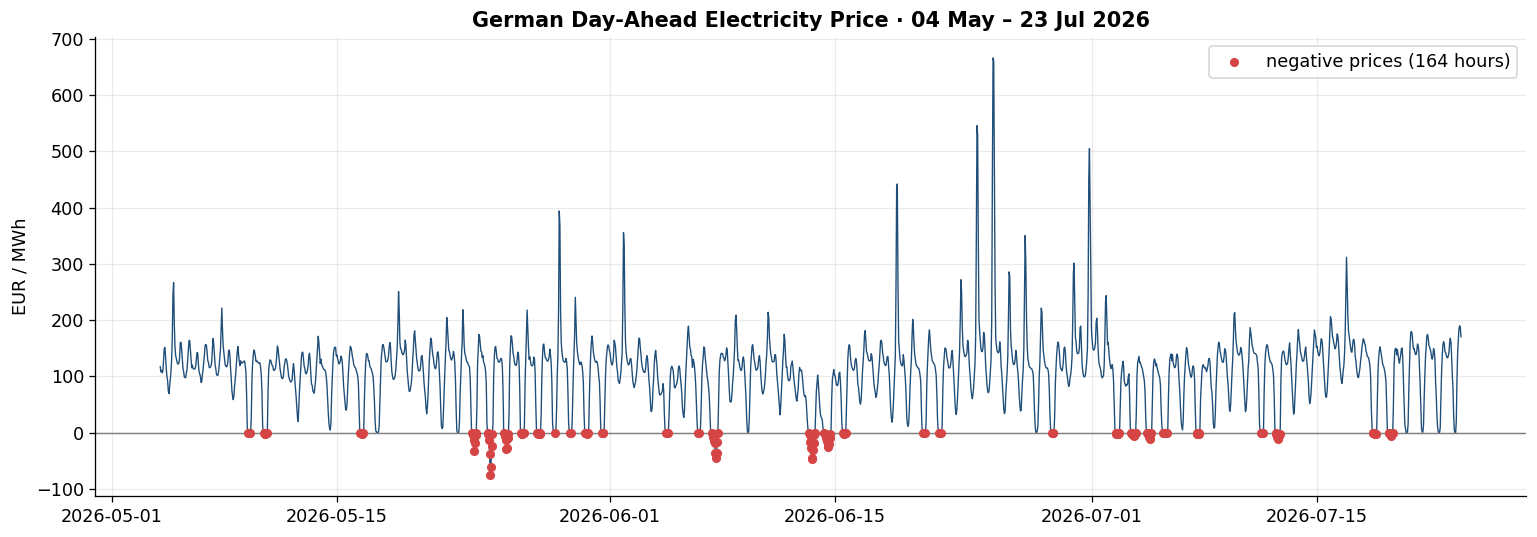

In [19]:
fig, ax = plt.subplots(figsize=(13.5, 4.8))
ax.plot(df.index, df.price, lw=0.85, color=DARK)
ax.scatter(neg.index, neg.price, color=RED, s=22, zorder=3,
           label=f"negative prices ({len(neg)} hours)")
ax.axhline(0, color="grey", lw=0.9)
ax.set_title(f"German Day-Ahead Electricity Price · {df.index.min():%d %b} – {df.index.max():%d %b %Y}")
ax.set_ylabel("EUR / MWh"); ax.legend(loc="upper right")
fig.tight_layout(); fig.savefig("01_timeseries.png", bbox_inches="tight"); plt.show()

## 5 · Chart 2 — The daily price shape (*duck curve*)

Average price per hour with the min–max range. The **midday valley** is solar pushing prices down; the **evening peak** is high demand after sunset. The price closely mirrors the famous *duck curve* of net demand (demand minus solar).

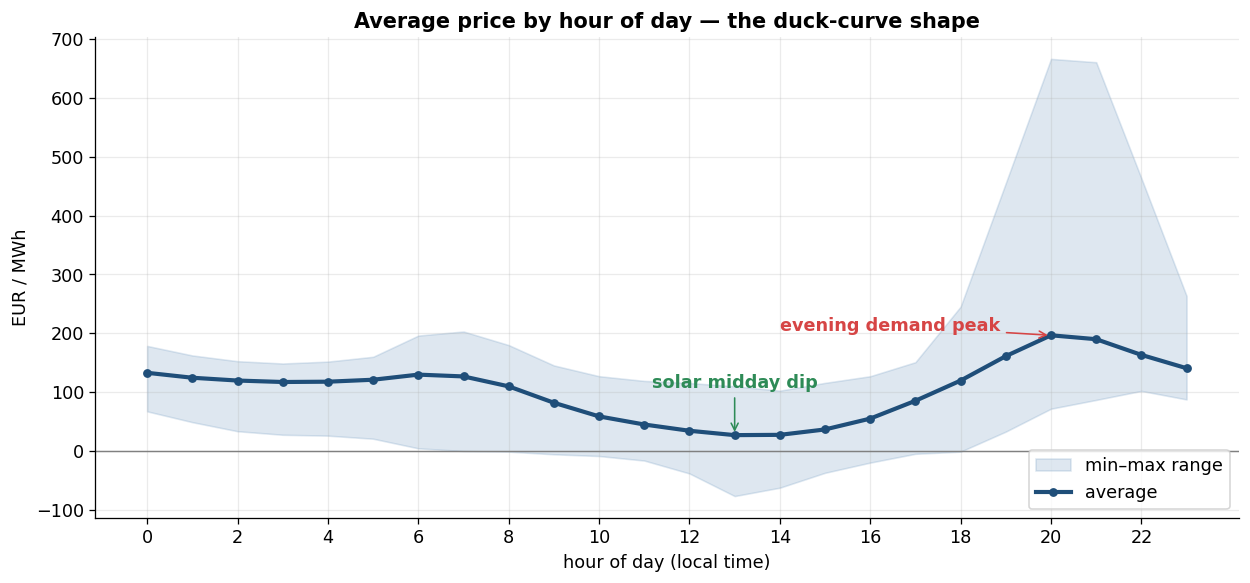

In [20]:
g = df.groupby("hour")["price"]
mean_h, min_h, max_h = g.mean(), g.min(), g.max()

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.fill_between(mean_h.index, min_h, max_h, alpha=0.18, color=BLUE, label="min–max range")
ax.plot(mean_h.index, mean_h.values, lw=2.6, color=DARK, marker="o", ms=4.5, label="average")
ax.axhline(0, color="grey", lw=0.9)
ax.annotate("solar midday dip", xy=(13, mean_h[13]), xytext=(13, mean_h.max()*0.55),
            ha="center", arrowprops=dict(arrowstyle="->", color=GREEN), color=GREEN, fontweight="bold")
ax.annotate("evening demand peak", xy=(int(mean_h.idxmax()), mean_h.max()),
            xytext=(int(mean_h.idxmax())-6, mean_h.max()*1.04),
            arrowprops=dict(arrowstyle="->", color=RED), color=RED, fontweight="bold")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day (local time)")
ax.set_ylabel("EUR / MWh"); ax.set_title("Average price by hour of day — the duck-curve shape")
ax.legend(loc="lower right"); fig.tight_layout()
fig.savefig("02_duck_curve.png", bbox_inches="tight"); plt.show()

## 6 · Chart 3 — Weekday vs weekend

Industrial and commercial demand drops on weekends — and so does the price.

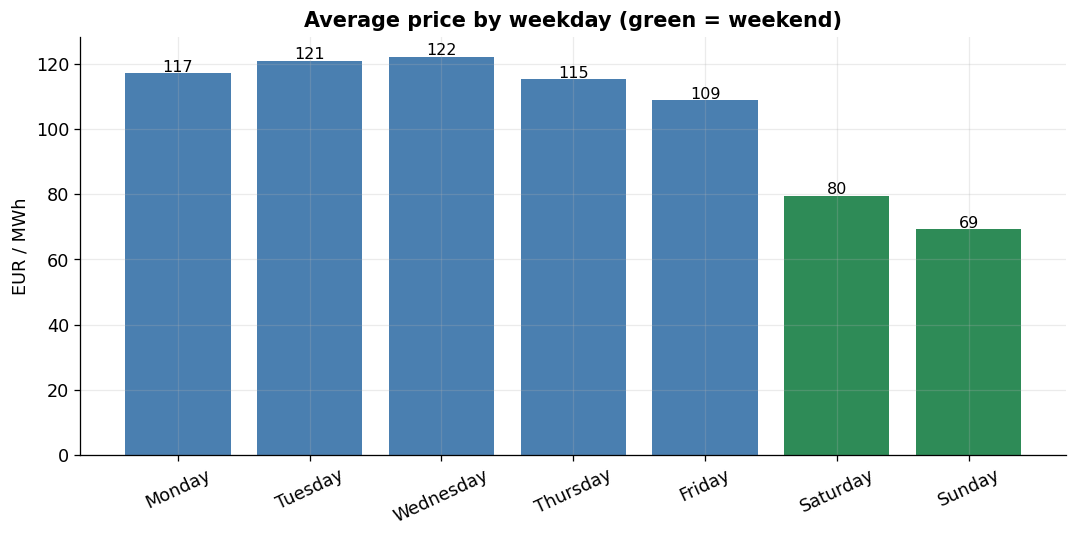

In [21]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
colors = [BLUE]*5 + [GREEN]*2
bars = ax.bar(by_wd.index, by_wd.values, color=colors)
for b, v in zip(bars, by_wd.values):
    ax.text(b.get_x()+b.get_width()/2, v + 0.5, f"{v:.0f}", ha="center", fontsize=10)
ax.set_title("Average price by weekday (green = weekend)")
ax.set_ylabel("EUR / MWh"); plt.xticks(rotation=25)
fig.tight_layout(); fig.savefig("03_weekday.png", bbox_inches="tight"); plt.show()

## 7 · Chart 4 — Heatmap: hour × weekday

The whole market in one picture: green = cheap (midday band, weekends), red = expensive (weekday evenings).

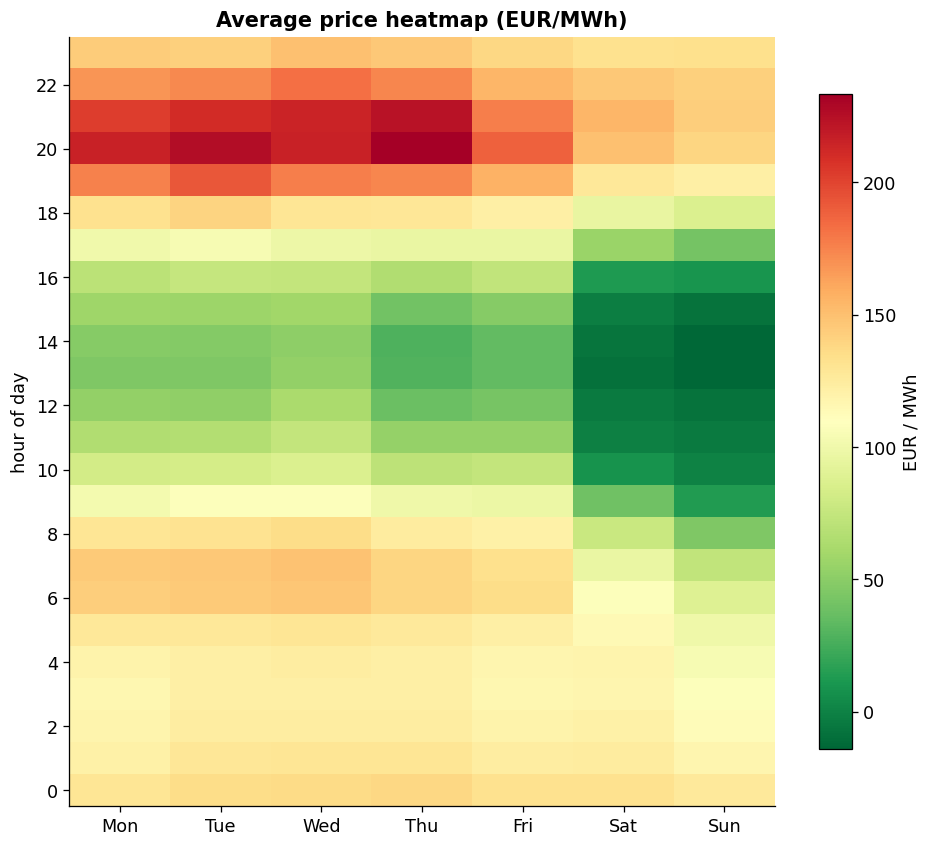

In [22]:
piv = df.pivot_table(index="hour", columns="weekday", values="price",
                     aggfunc="mean").reindex(columns=WEEKDAY_ORDER)
fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(piv, aspect="auto", cmap="RdYlGn_r", origin="lower")
ax.set_xticks(range(7)); ax.set_xticklabels([d[:3] for d in WEEKDAY_ORDER])
ax.set_yticks(range(0, 24, 2)); ax.set_ylabel("hour of day")
ax.set_title("Average price heatmap (EUR/MWh)")
ax.grid(False); fig.colorbar(im, label="EUR / MWh", shrink=0.85)
fig.tight_layout(); fig.savefig("04_heatmap.png", bbox_inches="tight"); plt.show()

## 8 · Chart 5 — Negative prices: when and how often?

Negative prices occur when wind + solar output exceeds what the grid needs and inflexible power plants can't shut down fast enough — producers pay buyers to take the surplus.

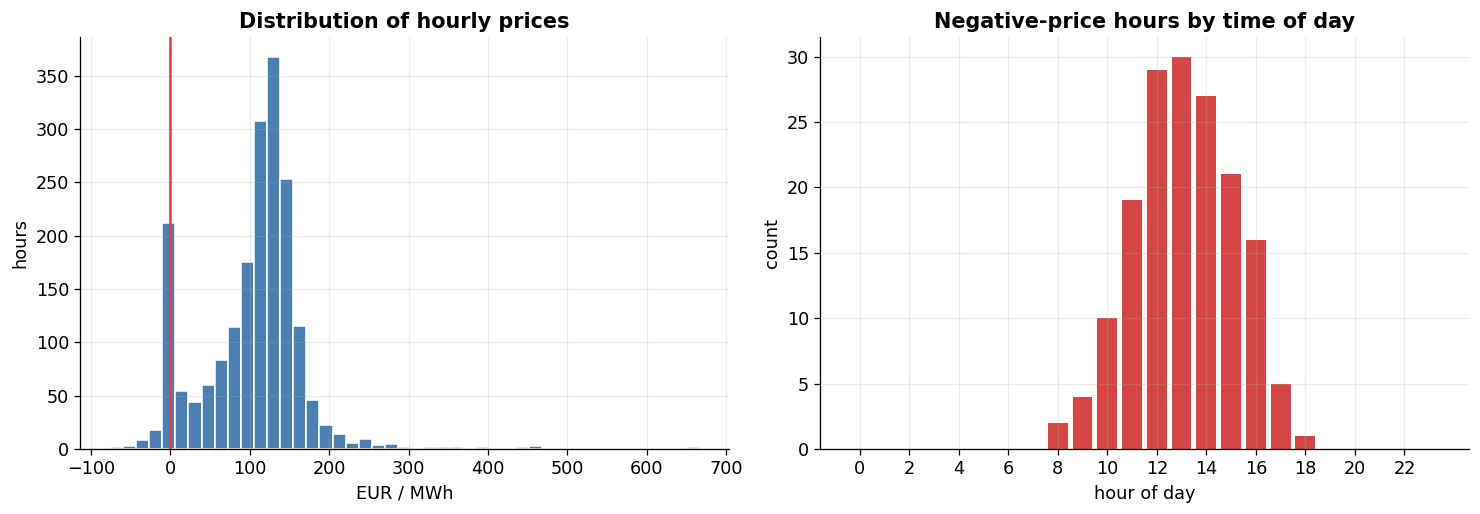

164 negative hours; most occur around 13:00 — typically sunny middays with high wind.


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].hist(df.price, bins=45, color=BLUE, edgecolor="white")
axes[0].axvline(0, color=RED, lw=1.6)
axes[0].set_title("Distribution of hourly prices")
axes[0].set_xlabel("EUR / MWh"); axes[0].set_ylabel("hours")

neg_by_hour = neg.groupby("hour").size().reindex(range(24), fill_value=0)
axes[1].bar(neg_by_hour.index, neg_by_hour.values, color=RED)
axes[1].set_title("Negative-price hours by time of day")
axes[1].set_xlabel("hour of day"); axes[1].set_ylabel("count")
axes[1].set_xticks(range(0, 24, 2))

fig.tight_layout(); fig.savefig("05_negative_prices.png", bbox_inches="tight"); plt.show()

if len(neg):
    print(f"{len(neg)} negative hours; most occur around "
          f"{neg_by_hour.idxmax():02d}:00 — typically sunny middays with high wind.")
else:
    print("No negative hours in this period — try a longer WEEKS_BACK or a sunnier season.")

## 9 · Chart 6 — The most recent trading day, hour by hour

This is your *“yesterday’s electricity prices”* chart — perfect for a LinkedIn post.

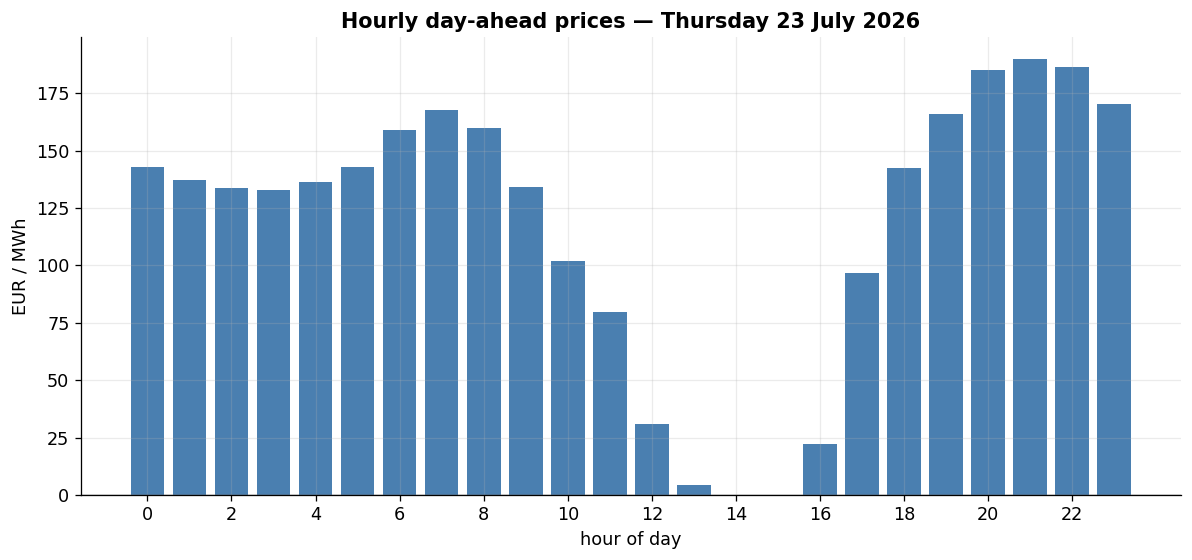

Thursday 23 July 2026: min 0.00 at 14:00, max 190.00 at 21:00 → spread of 190.00 EUR/MWh within one day


In [24]:
last_date = sorted(df["date"].unique())[-1]
last = df[df["date"] == last_date]

fig, ax = plt.subplots(figsize=(10.5, 5))
colors = [RED if p < 0 else GREEN if p == last.price.min() else BLUE for p in last.price]
bars = ax.bar(last["hour"], last["price"], color=colors)
ax.axhline(0, color="grey", lw=0.9)
ax.set_title(f"Hourly day-ahead prices — {pd.Timestamp(last_date):%A %d %B %Y}")
ax.set_xlabel("hour of day"); ax.set_ylabel("EUR / MWh"); ax.set_xticks(range(0, 24, 2))
fig.tight_layout(); fig.savefig("06_latest_day.png", bbox_inches="tight"); plt.show()

print(f"{pd.Timestamp(last_date):%A %d %B %Y}: "
      f"min {last.price.min():.2f} at {last.price.idxmin():%H:%M}, "
      f"max {last.price.max():.2f} at {last.price.idxmax():%H:%M} "
      f"→ spread of {last.price.max()-last.price.min():.2f} EUR/MWh within one day")

In [25]:
summary.to_csv("price_summary.csv", index=False)
print("Saved price_summary.csv")


Saved price_summary.csv


## 10 · Findings

From the run above (4 May to 23 July 2026, 1,944 hourly prices):

- **Volatility:** prices ranged from **−75.94** to **665.82 EUR/MWh**, a range of 741.76 EUR/MWh within twelve weeks (average 105.48, standard deviation 66.46).
- **Duck curve:** cheapest on average at **13:00 (27.5 EUR/MWh)**, when solar peaks; priciest at **20:00 (196.9 EUR/MWh)**, after sunset.
- **Weekend effect:** weekends averaged **42.56 EUR/MWh below weekdays**.
- **Negative prices:** **164 hours (8.4%)**, concentrated around 13:00, when renewables exceed demand.
- **Latest day:** on Thursday 23 July 2026 the price went from **0.00 at 14:00 to 190.00 at 21:00**, a spread of 190 EUR/MWh within one day.

**Why it matters:** these patterns are exactly what battery storage, flexible industry and energy traders monetise — buy the midday valley, sell the evening peak. The forecasting step (`forecast.py`) builds on them to predict tomorrow's prices.

---
*Data: Bundesnetzagentur | SMARD.de (EPEX SPOT day-ahead auction, DE/LU). Tools: Python, pandas, matplotlib.*